# Forecasting Model Comparison Report

This notebook reads existing test artifacts only. It does not retrain any model. It creates report-ready tables and charts for XGBoost, Extra Trees Regressor (ETR), and the stacking ensemble.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

if Path("/content").exists():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "artifacts").exists():
    drive_root = Path("/content/drive/MyDrive/demand-forecasting")
    if drive_root.exists():
        PROJECT_ROOT = drive_root

DOMAINS = ("demand", "price")
VARIANTS = ("core", "full")

DOMAIN_CONFIG = {
    "demand": {
        "target": "future_demand_kg",
        "unit": "kg",
        "title": "Demand",
    },
    "price": {
        "target": "future_weighted_avg_procurement_price_rm_per_kg",
        "unit": "RM/kg",
        "title": "Procurement Price",
    },
}

sns.set_theme(style="whitegrid", context="notebook")
print(f"Project root: {PROJECT_ROOT}")

Project root: c:\demand-forecasting


## Load and standardize saved test results

The XGBoost and ETR rows are read from their saved metric reports. Stacking metrics are calculated from the saved stacking test predictions because the stacking notebooks store their detailed comparison rows.

In [2]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual).sum()
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "WAPE (%)": float(np.abs(actual - predicted).sum() / denominator * 100) if denominator else np.nan,
        "R²": float(r2_score(actual, predicted)),
    }


def newest_file(directory, pattern):
    matches = list(directory.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern} in {directory}")
    return max(matches, key=lambda path: path.stat().st_mtime)


def load_reported_model(report_dir, pattern, expected_model, display_name):
    path = newest_file(report_dir, pattern)
    metrics = pd.read_csv(path)
    overall = metrics[
        (metrics["split"].astype(str).str.lower() == "test")
        & (metrics["forecast_horizon"].astype(str).str.lower() == "overall")
        & (metrics["model"].astype(str).str.lower() == expected_model)
    ]
    if len(overall) != 1:
        raise ValueError(f"Expected one overall test row in {path}; found {len(overall)}.")
    row = overall.iloc[0]
    return {
        "Model": display_name,
        "Test rows": int(row["rows"]),
        "MAE": float(row["mae"]),
        "RMSE": float(row["rmse"]),
        "WAPE (%)": float(row["wape"] * 100),
        "R²": float(row["r2"]),
    }


def load_stacking(prediction_dir, target_column):
    path = newest_file(prediction_dir, "stacking_test_comparison*.csv")
    predictions = pd.read_csv(path)
    required = {target_column, "stacking_prediction"}
    missing = required.difference(predictions.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")
    result = calculate_metrics(predictions[target_column], predictions["stacking_prediction"])
    return {"Model": "Stacking Ensemble", "Test rows": len(predictions), **result}


def build_comparison(domain, variant):
    artifact_root = PROJECT_ROOT / "artifacts" / domain / variant
    report_dir = artifact_root / "reports"
    prediction_dir = artifact_root / "predictions"
    rows = [
        load_reported_model(report_dir, "xgboost_metrics*.csv", "xgboost", "XGBoost"),
        load_reported_model(report_dir, "etr_metrics.csv", "etr", "Extra Trees Regressor"),
        load_stacking(prediction_dir, DOMAIN_CONFIG[domain]["target"]),
    ]
    comparison = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
    comparison.insert(0, "Rank", np.arange(1, len(comparison) + 1))
    comparison.insert(1, "Variant", variant.capitalize())
    return comparison

## Report-ready model comparison outputs

For every domain and variant, the first output is the formatted test table. The next figure compares error metrics, followed by a separate R² chart. Lower MAE, RMSE and WAPE are better; higher R² is better.


DEMAND MODEL COMPARISON — CORE VARIANT


,Rank,Variant,Model,Test rows,MAE,RMSE,WAPE (%),R²
0,1,Core,XGBoost,1620,533.243,670.939,20.49,0.536
1,2,Core,Stacking Ensemble,1620,545.587,688.513,20.97,0.511
2,3,Core,Extra Trees Regressor,1620,586.310,749.647,22.53,0.421


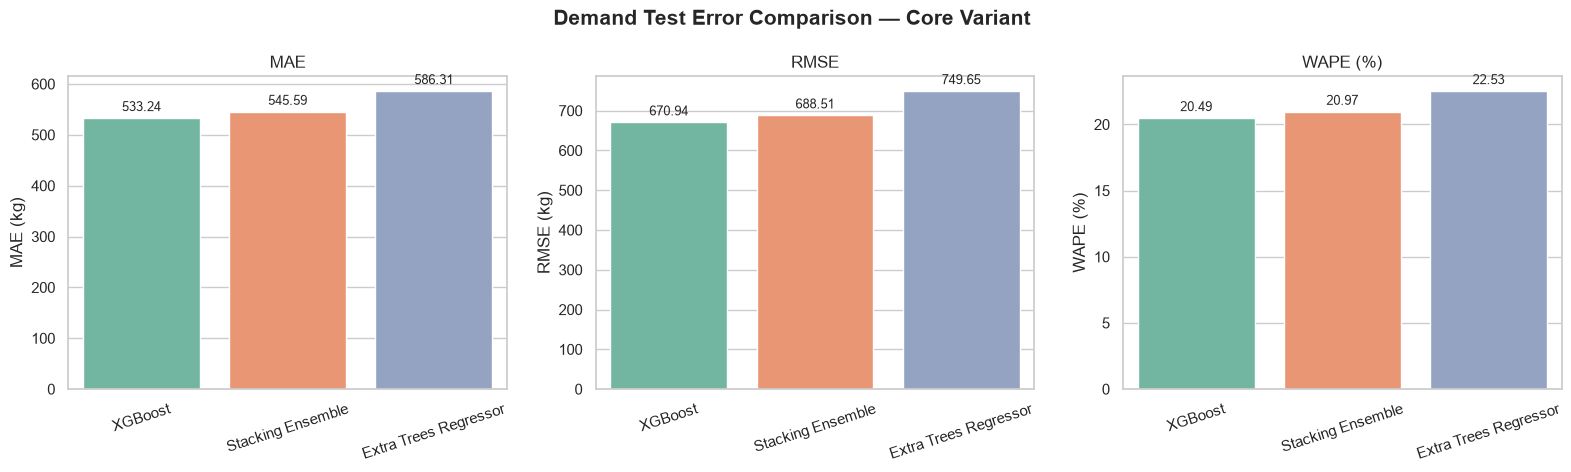

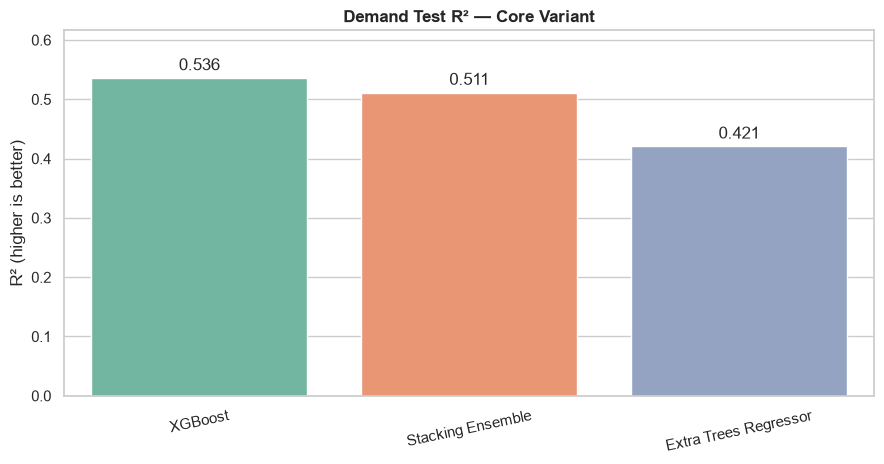

Saved table: c:\demand-forecasting\artifacts\demand\core\reports\model_comparison\test_metrics_comparison.csv
Saved charts: test_error_comparison.png, test_r2_comparison.png

DEMAND MODEL COMPARISON — FULL VARIANT


,Rank,Variant,Model,Test rows,MAE,RMSE,WAPE (%),R²
0,1,Full,XGBoost,1620,536.377,672.492,20.61,0.534
1,2,Full,Stacking Ensemble,1620,543.638,684.364,20.89,0.517
2,3,Full,Extra Trees Regressor,1620,581.991,747.231,22.37,0.425


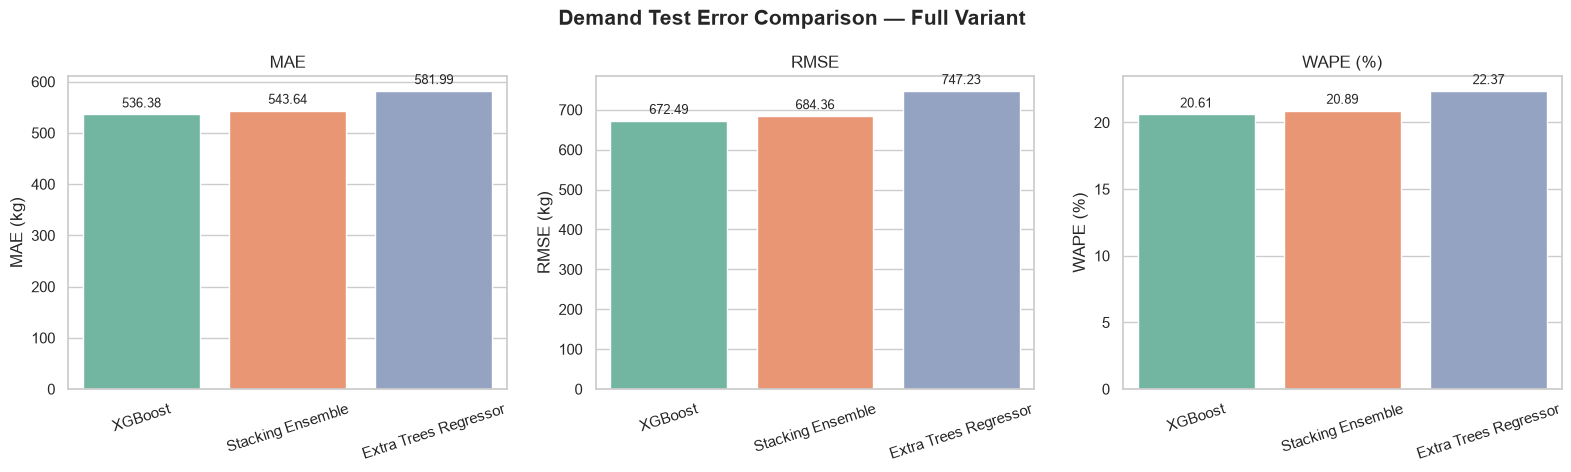

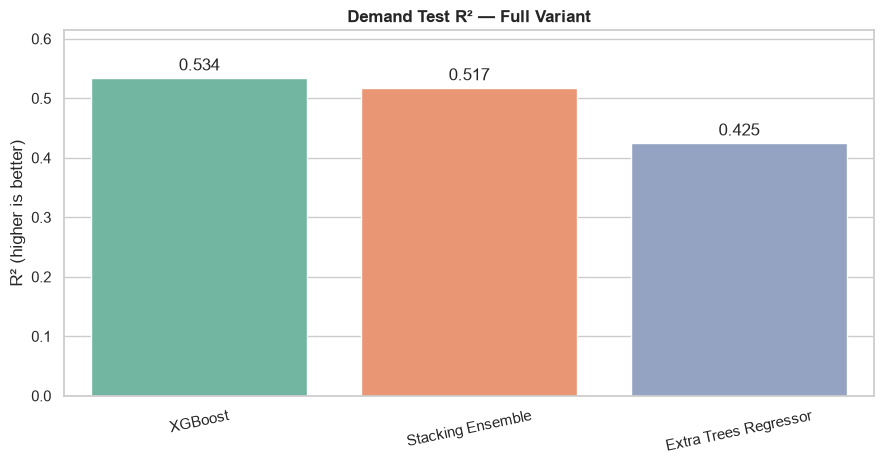

Saved table: c:\demand-forecasting\artifacts\demand\full\reports\model_comparison\test_metrics_comparison.csv
Saved charts: test_error_comparison.png, test_r2_comparison.png

PROCUREMENT PRICE MODEL COMPARISON — CORE VARIANT


,Rank,Variant,Model,Test rows,MAE,RMSE,WAPE (%),R²
0,1,Core,XGBoost,1620,0.148,0.197,3.25,0.988
1,2,Core,Stacking Ensemble,1620,0.151,0.205,3.31,0.987
2,3,Core,Extra Trees Regressor,1620,0.171,0.214,3.74,0.986


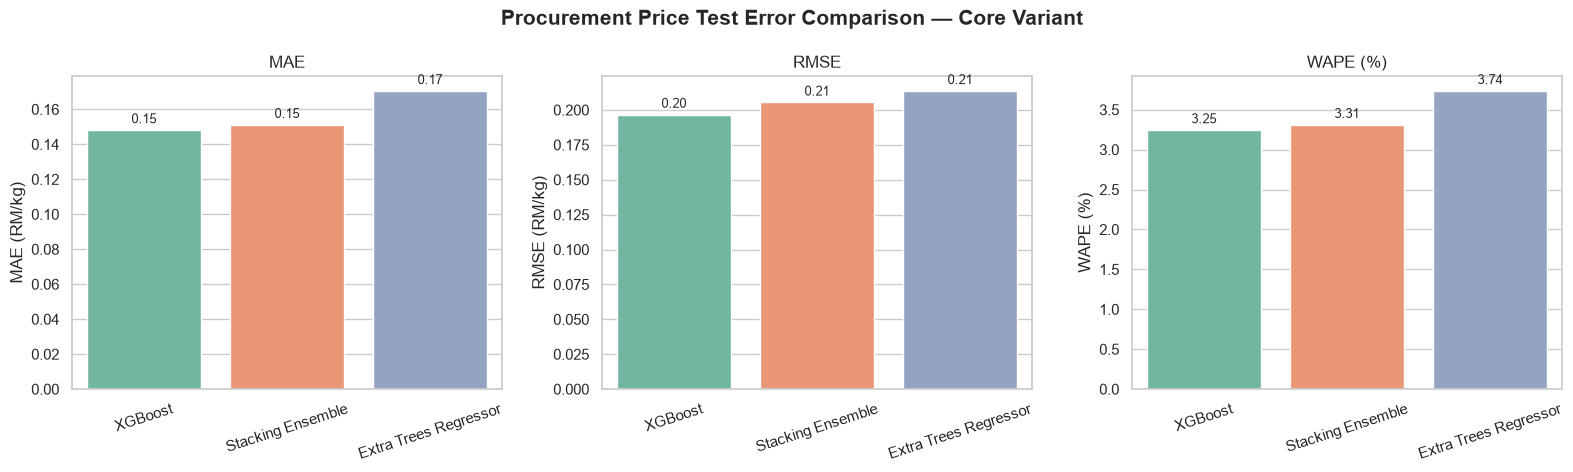

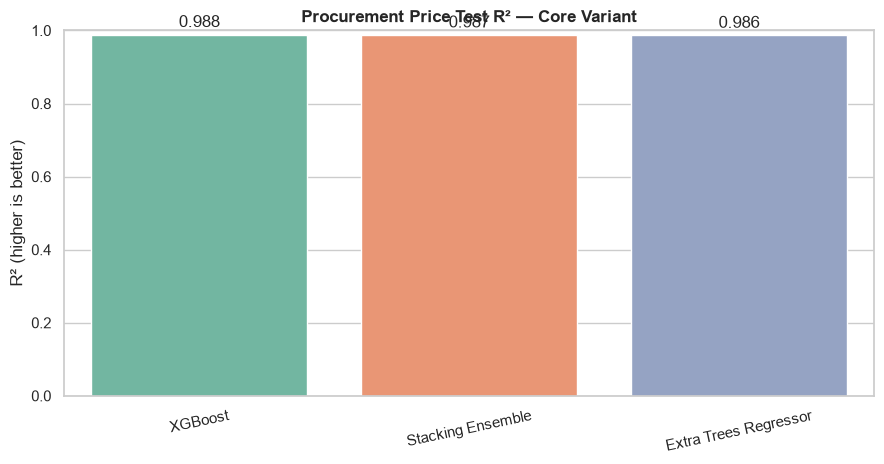

Saved table: c:\demand-forecasting\artifacts\price\core\reports\model_comparison\test_metrics_comparison.csv
Saved charts: test_error_comparison.png, test_r2_comparison.png

PROCUREMENT PRICE MODEL COMPARISON — FULL VARIANT


,Rank,Variant,Model,Test rows,MAE,RMSE,WAPE (%),R²
0,1,Full,XGBoost,1620,0.148,0.197,3.25,0.988
1,2,Full,Stacking Ensemble,1620,0.152,0.208,3.34,0.987
2,3,Full,Extra Trees Regressor,1620,0.170,0.213,3.73,0.986


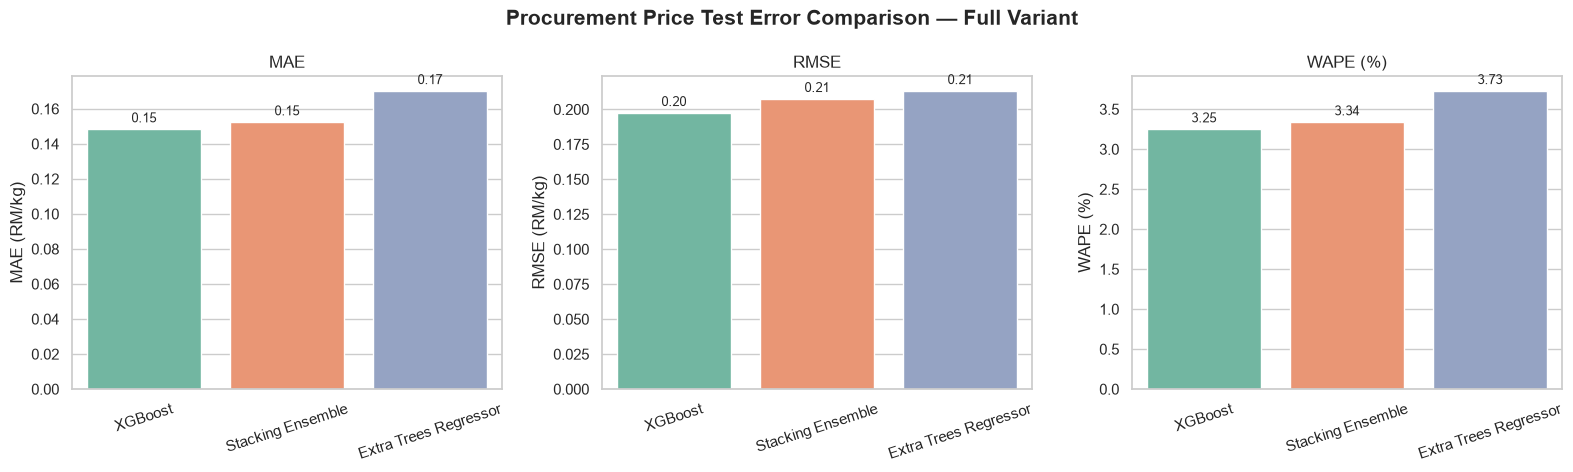

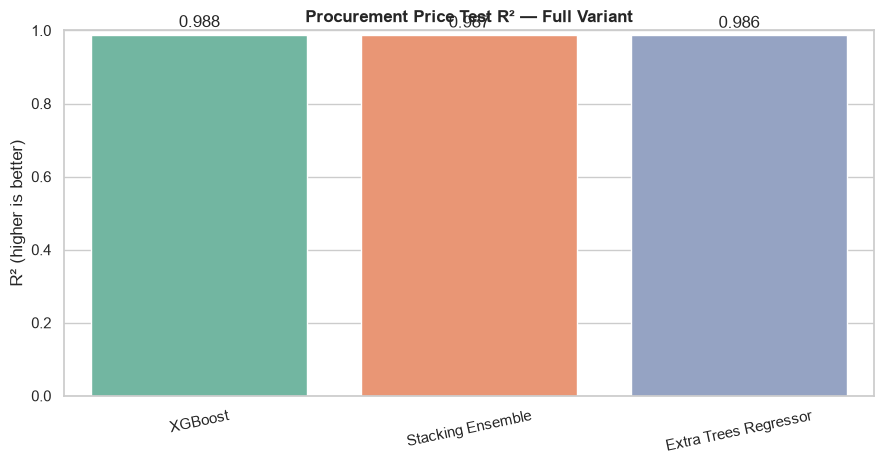

Saved table: c:\demand-forecasting\artifacts\price\full\reports\model_comparison\test_metrics_comparison.csv
Saved charts: test_error_comparison.png, test_r2_comparison.png


In [3]:
all_comparisons = {}

for domain in DOMAINS:
    config = DOMAIN_CONFIG[domain]
    for variant in VARIANTS:
        comparison = build_comparison(domain, variant)
        all_comparisons[(domain, variant)] = comparison

        output_dir = PROJECT_ROOT / "artifacts" / domain / variant / "reports" / "model_comparison"
        output_dir.mkdir(parents=True, exist_ok=True)
        comparison.to_csv(output_dir / "test_metrics_comparison.csv", index=False)

        print(f"\n{config['title'].upper()} MODEL COMPARISON — {variant.upper()} VARIANT")
        formatted = comparison.copy()
        formatted["MAE"] = formatted["MAE"].round(3)
        formatted["RMSE"] = formatted["RMSE"].round(3)
        formatted["WAPE (%)"] = formatted["WAPE (%)"].round(2)
        formatted["R²"] = formatted["R²"].round(3)
        display(formatted)

        fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
        chart_specs = [
            ("MAE", f"MAE ({config['unit']})"),
            ("RMSE", f"RMSE ({config['unit']})"),
            ("WAPE (%)", "WAPE (%)"),
        ]
        for axis, (metric, label) in zip(axes, chart_specs):
            sns.barplot(data=comparison, x="Model", y=metric, hue="Model", legend=False, ax=axis, palette="Set2")
            axis.set_title(metric)
            axis.set_xlabel("")
            axis.set_ylabel(label)
            axis.tick_params(axis="x", rotation=18)
            for container in axis.containers:
                axis.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
        fig.suptitle(f"{config['title']} Test Error Comparison — {variant.capitalize()} Variant", fontsize=15, fontweight="bold")
        plt.tight_layout()
        error_path = output_dir / "test_error_comparison.png"
        plt.savefig(error_path, dpi=220, bbox_inches="tight")
        plt.show()

        plt.figure(figsize=(9, 4.8))
        axis = sns.barplot(data=comparison, x="Model", y="R²", hue="Model", legend=False, palette="Set2")
        axis.set_title(f"{config['title']} Test R² — {variant.capitalize()} Variant", fontweight="bold")
        axis.set_xlabel("")
        axis.set_ylabel("R² (higher is better)")
        axis.tick_params(axis="x", rotation=12)
        lower = min(0, comparison["R²"].min() - 0.05)
        upper = min(1.0, comparison["R²"].max() + 0.08)
        axis.set_ylim(lower, upper)
        for container in axis.containers:
            axis.bar_label(container, fmt="%.3f", padding=3)
        plt.tight_layout()
        r2_path = output_dir / "test_r2_comparison.png"
        plt.savefig(r2_path, dpi=220, bbox_inches="tight")
        plt.show()

        print(f"Saved table: {output_dir / 'test_metrics_comparison.csv'}")
        print(f"Saved charts: {error_path.name}, {r2_path.name}")

## Demand XGBoost hyperparameter tuning evidence

Panel one presents the five best chronological-validation trials ranked by mean fold WAPE. Panel two presents the selected configuration and final held-out test performance.

In [ ]:
tuning_report_dir = PROJECT_ROOT / "artifacts" / "demand" / "core" / "reports"
comparison_output_dir = tuning_report_dir / "model_comparison"
comparison_output_dir.mkdir(parents=True, exist_ok=True)

leaderboard = pd.read_csv(tuning_report_dir / "xgboost_tuning_leaderboard.csv").head(5).copy()
leaderboard_display = leaderboard[["candidate", "max_depth", "learning_rate", "min_child_weight", "subsample", "colsample_bytree", "n_estimators", "mean_fold_wape"]].copy()
leaderboard_display.columns = ["Trial", "Depth", "Learning rate", "Min child weight", "Row sample", "Feature sample", "Trees", "Mean CV WAPE"]
leaderboard_display["Mean CV WAPE"] = (leaderboard_display["Mean CV WAPE"] * 100).round(2).astype(str) + "%"
for column in ["Learning rate", "Row sample", "Feature sample"]:
    leaderboard_display[column] = leaderboard_display[column].map(lambda value: f"{value:.2f}")
display(leaderboard_display)

fig, axis = plt.subplots(figsize=(15, 3.6))
axis.axis("off")
table = axis.table(cellText=leaderboard_display.values, colLabels=leaderboard_display.columns, cellLoc="center", colLoc="center", loc="center")
table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1, 1.65)
for (row, column), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#2f6f4e")
        cell.set_text_props(color="white", weight="bold")
    elif row == 1:
        cell.set_facecolor("#dff0e6")
axis.set_title("Top Five Demand XGBoost Tuning Trials", fontsize=15, fontweight="bold", pad=16)
plt.tight_layout()
leaderboard_figure = comparison_output_dir / "xgboost_tuning_leaderboard.png"
plt.savefig(leaderboard_figure, dpi=220, bbox_inches="tight")
plt.show()

metadata = json.loads((tuning_report_dir / "xgboost_tuning_metadata.json").read_text(encoding="utf-8"))
parameters = metadata["selected_parameters"]
test_metrics = metadata["test_metrics"]
selected_display = pd.DataFrame([
    ("Selected trial", metadata["selected_candidate"]),
    ("Selection metric", "Mean fold WAPE"),
    ("Chronological folds", metadata["folds"]),
    ("Validation months per fold", metadata["validation_months_per_fold"]),
    ("Maximum tree depth", parameters["max_depth"]),
    ("Learning rate", parameters["learning_rate"]),
    ("Minimum child weight", parameters["min_child_weight"]),
    ("Row sampling", parameters["subsample"]),
    ("Feature sampling", parameters["colsample_bytree"]),
    ("Number of trees", parameters["n_estimators"]),
    ("Test MAE", f"{test_metrics['mae']:.2f} kg"),
    ("Test RMSE", f"{test_metrics['rmse']:.2f} kg"),
    ("Test WAPE", f"{test_metrics['wape'] * 100:.2f}%"),
    ("Test R²", f"{test_metrics['r2']:.3f}"),
], columns=["Item", "Selected value"])
display(selected_display)

fig, axis = plt.subplots(figsize=(8.5, 7.2))
axis.axis("off")
table = axis.table(cellText=selected_display.values, colLabels=selected_display.columns, cellLoc="left", colLoc="left", loc="center", colWidths=[0.6, 0.4])
table.auto_set_font_size(False)
table.set_fontsize(10.5)
table.scale(1, 1.48)
for (row, column), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#2f6f4e")
        cell.set_text_props(color="white", weight="bold")
    elif row >= 11:
        cell.set_facecolor("#eef6f1")
axis.set_title("Selected Demand XGBoost Configuration and Test Performance", fontsize=14, fontweight="bold", pad=16)
plt.tight_layout()
selected_figure = comparison_output_dir / "xgboost_selected_parameters.png"
plt.savefig(selected_figure, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved tuning figures: {leaderboard_figure}, {selected_figure}")

## Test MAE across direct forecast horizons H1–H12

These figures show whether forecast error changes as the prediction distance increases. Each line uses the same chronological test set as the overall model comparison.

In [ ]:
def load_reported_horizons(report_dir, pattern, expected_model, display_name):
    path = newest_file(report_dir, pattern)
    metrics = pd.read_csv(path)
    horizon = metrics[
        (metrics["split"].astype(str).str.lower() == "test")
        & (metrics["forecast_horizon"].astype(str).str.lower() != "overall")
        & (metrics["model"].astype(str).str.lower() == expected_model)
    ].copy()
    horizon["forecast_horizon"] = pd.to_numeric(horizon["forecast_horizon"]).astype(int)
    return horizon[["forecast_horizon", "mae"]].assign(Model=display_name)


def load_stacking_horizons(prediction_dir, target_column):
    path = newest_file(prediction_dir, "stacking_test_comparison*.csv")
    predictions = pd.read_csv(path)
    rows = []
    for horizon, group in predictions.groupby("forecast_horizon"):
        rows.append({
            "forecast_horizon": int(horizon),
            "mae": float(mean_absolute_error(group[target_column], group["stacking_prediction"])),
            "Model": "Stacking Ensemble",
        })
    return pd.DataFrame(rows)


def build_horizon_comparison(domain, variant):
    artifact_root = PROJECT_ROOT / "artifacts" / domain / variant
    report_dir = artifact_root / "reports"
    prediction_dir = artifact_root / "predictions"
    return pd.concat([
        load_reported_horizons(report_dir, "xgboost_metrics*.csv", "xgboost", "XGBoost"),
        load_reported_horizons(report_dir, "etr_metrics.csv", "etr", "Extra Trees Regressor"),
        load_stacking_horizons(prediction_dir, DOMAIN_CONFIG[domain]["target"]),
    ], ignore_index=True).sort_values(["Model", "forecast_horizon"])


for domain in DOMAINS:
    config = DOMAIN_CONFIG[domain]
    for variant in VARIANTS:
        horizon_comparison = build_horizon_comparison(domain, variant)
        output_dir = PROJECT_ROOT / "artifacts" / domain / variant / "reports" / "model_comparison"
        output_dir.mkdir(parents=True, exist_ok=True)
        horizon_comparison.to_csv(output_dir / "test_mae_by_horizon.csv", index=False)

        plt.figure(figsize=(11, 5.5))
        axis = sns.lineplot(
            data=horizon_comparison,
            x="forecast_horizon",
            y="mae",
            hue="Model",
            style="Model",
            marker="o",
            linewidth=2.2,
        )
        axis.set_title(f"{config['title']} Test MAE by Forecast Horizon — {variant.capitalize()} Variant", fontweight="bold")
        axis.set_xlabel("Direct forecast horizon")
        axis.set_ylabel(f"MAE ({config['unit']})")
        axis.set_xticks(range(1, 13), [f"H{value}" for value in range(1, 13)])
        axis.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        horizon_path = output_dir / "test_mae_by_horizon.png"
        plt.savefig(horizon_path, dpi=220, bbox_inches="tight")
        plt.show()
        print(f"Saved horizon figure: {horizon_path}")

## XGBoost core-versus-full contextual comparison

This final table isolates the effect of optional contextual inputs by comparing the same XGBoost algorithm across the core and full variants. It should be reported separately from the algorithm comparison.

In [4]:
for domain in DOMAINS:
    rows = []
    for variant in VARIANTS:
        row = all_comparisons[(domain, variant)].query("Model == 'XGBoost'").iloc[0].copy()
        rows.append(row)
    context_comparison = pd.DataFrame(rows).drop(columns=["Rank"]).reset_index(drop=True)
    print(f"\n{DOMAIN_CONFIG[domain]['title'].upper()} XGBOOST CONTEXT COMPARISON")
    formatted = context_comparison.copy()
    formatted["MAE"] = formatted["MAE"].round(3)
    formatted["RMSE"] = formatted["RMSE"].round(3)
    formatted["WAPE (%)"] = formatted["WAPE (%)"].round(2)
    formatted["R²"] = formatted["R²"].round(3)
    display(formatted)


DEMAND XGBOOST CONTEXT COMPARISON


,Variant,Model,Test rows,MAE,RMSE,WAPE (%),R²
0,Core,XGBoost,1620,533.243,670.939,20.49,0.536
1,Full,XGBoost,1620,536.377,672.492,20.61,0.534



PROCUREMENT PRICE XGBOOST CONTEXT COMPARISON


,Variant,Model,Test rows,MAE,RMSE,WAPE (%),R²
0,Core,XGBoost,1620,0.148,0.197,3.25,0.988
1,Full,XGBoost,1620,0.148,0.197,3.25,0.988
